# 2 · Classification

Six classifiers are trained on the segment features from notebook 1 and evaluated with three protocols:

1. **Random stratified split (80/20)** – the protocol required by the project. Files are split, so segments of one clip never
   cross the split, but the same *narrator* appears in train and test.
2. **Contributor-disjoint 5-fold CV** – no contributor in two folds. Looks speaker-independent, but notebook 1 showed that
   contributors share audiobooks.
3. **Leave-one-narrator-out (LONO)** – each of the ~24 estimated narrators is held out once:
   *does the model recognise the language of a voice it has never heard?*

Detailed metrics and plots are in notebook 4 (Evaluation); here the focus is on preprocessing, model selection and training.

In [1]:
%load_ext autoreload
%autoreload 2
import os, warnings; warnings.filterwarnings("ignore"); os.environ["PYTHONWARNINGS"] = "ignore"  # also silences joblib workers
import time, joblib, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from slid import config as C, features, models, plotting
plotting.setup(); C.ensure_dirs()

meta = pd.read_parquet(C.PROCESSED_DIR / "metadata.parquet")
seg = pd.read_parquet(C.PROCESSED_DIR / "segment_features.parquet")
seg = seg.merge(meta[["file_id", "label", "language", "gender", "contributor", "narrator", "split", "contributor_fold"]], on="file_id")
FEATS = features.feature_columns(seg.columns)
PROBA = [f"p_{l}" for l in C.LANGUAGES]
print(len(FEATS), "features")

381 features


## 2.1 Data splitting

* **Train:** all segments of training files – original audio **plus** the three augmented copies.
* **Test:** original segments of test files only (augmentation is never applied to evaluation data).

In [2]:
train = seg[seg.split == "train"].reset_index(drop=True)
test = seg[(seg.split == "test") & (seg.aug == "none")].reset_index(drop=True)
tbl = pd.DataFrame({
    "train files": train.drop_duplicates("file_id").groupby("language").size(),
    "train segments (incl. aug.)": train.groupby("language").size(),
    "test files": test.drop_duplicates("file_id").groupby("language").size(),
    "test segments": test.groupby("language").size(),
})
tbl.loc["total"] = tbl.sum(); tbl

,train files,train segments (incl. aug.),test files,test segments
language,,,,
German,144,3149,36,195
Italian,143,3270,36,199
Korean,144,2934,36,183
Spanish,144,3220,36,200
total,575,12573,144,777


## 2.2 Preprocessing

Every model is a `Pipeline` fitted on training data only:

1. **Median imputation** – a few prosody features are undefined when a segment has almost no voiced frames.
2. **Standardisation** (z-score) – features live on very different scales (Hz, dB, ratios); distance- and gradient-based
   models (KNN, SVM, MLP, logistic regression) need comparable scales.
3. **Dimensionality reduction (model-dependent)** – PCA keeping 95 % of variance, or LDA (3 components = #classes − 1).
   Tried for KNN, where distances in 381-D are unreliable, and used for Naïve Bayes, whose independence assumption fits
   decorrelated PCA components better than strongly correlated raw features.

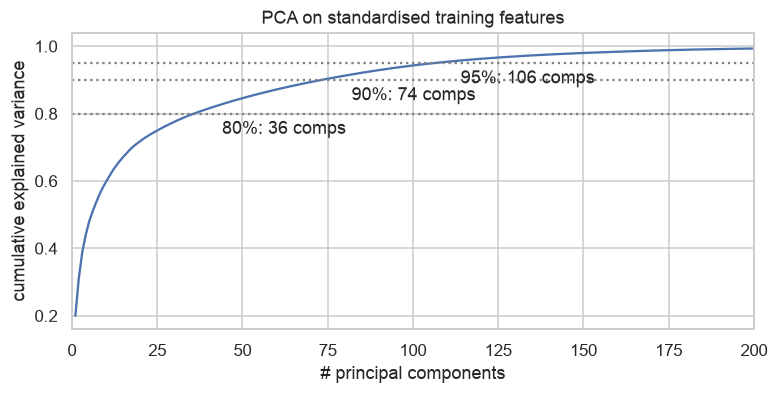

In [3]:
Z = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(train.loc[train.aug == "none", FEATS]))
pca = PCA().fit(Z)
cum = np.cumsum(pca.explained_variance_ratio_)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(np.arange(1, len(cum) + 1), cum)
for t in (0.8, 0.9, 0.95):
    k = int(np.searchsorted(cum, t) + 1); ax.axhline(t, ls=":", c="gray"); ax.annotate(f"{t:.0%}: {k} comps", (k, t), xytext=(k + 8, t - 0.06))
ax.set_xlabel("# principal components"); ax.set_ylabel("cumulative explained variance"); ax.set_xlim(0, 200)
ax.set_title("PCA on standardised training features"); plotting.save(fig, "02_pca_variance")

The features are highly redundant (e.g. MFCCs, log-mel and LPC all describe the spectral envelope): far fewer components
than 381 explain 95 % of the variance.

## 2.3 Models and hyper-parameter search

| Model | Why it is included |
|---|---|
| Logistic Regression | strong linear baseline, well-calibrated probabilities, robust in high dimensions |
| SVM (RBF) | margin-based, handles non-linear class boundaries; historically strong for LID on utterance vectors |
| KNN (+PCA/LDA) | non-parametric; shows how much local similarity in feature space reflects language |
| Random Forest | non-linear, insensitive to scaling, gives feature importances |
| MLP | flexible non-linear model; the closest to a neural approach without deep learning frameworks |
| Gaussian Naïve Bayes (+PCA) | simple generative baseline |

Hyper-parameters are chosen with 5-fold CV **inside the training set**, grouped by file (no clip in two folds), training
on augmented data and validating on original audio only; the score is macro-F1 on segments.

In [4]:
X_tr, y_tr = train[FEATS].to_numpy(), train.label.to_numpy()
X_te, y_te = test[FEATS].to_numpy(), test.label.to_numpy()
cv = models.file_group_cv(train)

best, rows = {}, []
for name, (pipe, grid) in models.model_zoo().items():
    t0 = time.time()
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="f1_macro", n_jobs=-1, refit=True).fit(X_tr, y_tr)
    best[name] = gs.best_estimator_
    params = {k.split("__")[-1]: (type(v).__name__ if hasattr(v, "fit") else v) for k, v in gs.best_params_.items()}
    rows.append({"model": name, "cv_macro_f1": gs.best_score_, "cv_std": gs.cv_results_["std_test_score"][gs.best_index_],
                 "best_params": params, "time_s": time.time() - t0})
    joblib.dump(gs.best_estimator_, C.MODELS_DIR / f"{models.slug(name)}.joblib")
cv_table = pd.DataFrame(rows).set_index("model").sort_values("cv_macro_f1", ascending=False)
cv_table.to_csv(C.RESULTS_DIR / "cv_model_selection.csv")
cv_table

,cv_macro_f1,cv_std,best_params,time_s
model,,,,
SVM (RBF),0.999007,0.001985,"{'C': 1, 'gamma': 'scale'}",107.810680
Random Forest,0.998706,0.001925,"{'max_features': 'sqrt', 'min_samples_leaf': 1}",245.938563
KNN,0.998439,0.001671,"{'n_neighbors': 15, 'weights': 'distance', 're...",5.966299
MLP,0.998082,0.002351,{'alpha': 0.1},11.031778
Logistic Regression,0.996492,0.002328,{'C': 0.1},4.015483
Gaussian NB,0.955353,0.009104,{'var_smoothing': 1e-09},0.995650


## 2.4 Test-set predictions (random split)

Each model outputs class probabilities per 10 s segment. A **file-level** decision (≈ 1 minute of speech) is made by
averaging the probabilities of all segments of the file.

In [5]:
pred = []
for name, model in best.items():
    P = model.predict_proba(X_te)
    df = test[["file_id", "segment", "contributor", "narrator", "gender"]].copy()
    df["model"], df["y_true"] = name, y_te
    df[PROBA] = P; df["y_pred"] = P.argmax(1)
    pred.append(df)
pred = pd.concat(pred, ignore_index=True)
pred.to_csv(C.RESULTS_DIR / "random_split_predictions.csv", index=False)

file_pred = models.file_level(pred, PROBA)
summary = pd.DataFrame({
    "segment accuracy": pred.groupby("model").apply(lambda d: (d.y_true == d.y_pred).mean()),
    "segment macro-F1": pred.groupby("model").apply(lambda d: models.metrics(d.y_true, d.y_pred)["f1_macro"]),
    "file accuracy": file_pred.groupby("model").apply(lambda d: (d.y_true == d.y_pred).mean()),
    "file macro-F1": file_pred.groupby("model").apply(lambda d: models.metrics(d.y_true, d.y_pred)["f1_macro"]),
}).sort_values("file macro-F1", ascending=False)
summary

,segment accuracy,segment macro-F1,file accuracy,file macro-F1
model,,,,
KNN,0.998713,0.998689,1.000000,1.0000
Logistic Regression,0.996139,0.996156,1.000000,1.0000
MLP,0.997426,0.997426,1.000000,1.0000
Random Forest,0.998713,0.998689,1.000000,1.0000
SVM (RBF),0.998713,0.998689,1.000000,1.0000
Gaussian NB,0.962677,0.962994,0.986111,0.9861


## 2.5 Group-disjoint evaluation

The models (with the hyper-parameters selected above, no re-tuning) are retrained on every fold. Training folds use the
augmented copies; held-out files are evaluated on original audio only.

In [6]:
def run_fold(name, model, group_col, g):
    tr = seg[seg[group_col] != g]
    te = seg[(seg[group_col] == g) & (seg.aug == "none")]
    m = clone(model).fit(tr[FEATS].to_numpy(), tr.label.to_numpy())
    P = m.predict_proba(te[FEATS].to_numpy())
    df = te[["file_id", "segment", "contributor", "narrator", "gender"]].copy()
    df["model"], df["fold"], df["y_true"] = name, g, te.label.to_numpy()
    df[PROBA] = P; df["y_pred"] = P.argmax(1)
    return df

def summarize(p):
    f = models.file_level(p, PROBA)
    return pd.DataFrame({
        "segment accuracy": p.groupby("model").apply(lambda d: (d.y_true == d.y_pred).mean()),
        "segment macro-F1": p.groupby("model").apply(lambda d: models.metrics(d.y_true, d.y_pred)["f1_macro"]),
        "file accuracy": f.groupby("model").apply(lambda d: (d.y_true == d.y_pred).mean()),
        "file macro-F1": f.groupby("model").apply(lambda d: models.metrics(d.y_true, d.y_pred)["f1_macro"]),
    }).sort_values("file macro-F1", ascending=False)

results = {}
for protocol, group_col in [("contributor_cv", "contributor_fold"), ("narrator_lono", "narrator")]:
    t0 = time.time()
    groups = sorted(seg[group_col].unique())
    p = pd.concat(Parallel(n_jobs=-1)(delayed(run_fold)(n, m, group_col, g) for n, m in best.items() for g in groups),
                  ignore_index=True)
    p.to_csv(C.RESULTS_DIR / f"{protocol}_predictions.csv", index=False)
    results[protocol] = summarize(p)
    print(f"{protocol}: {len(groups)} folds, {time.time() - t0:.0f} s")

contributor_cv: 5 folds, 85 s


narrator_lono: 24 folds, 547 s


### Contributor-disjoint 5-fold CV

In [7]:
results["contributor_cv"]

,segment accuracy,segment macro-F1,file accuracy,file macro-F1
model,,,,
KNN,0.991327,0.991431,0.998609,0.998607
MLP,0.991071,0.991106,0.998609,0.998607
SVM (RBF),0.992857,0.992975,0.998609,0.998607
Random Forest,0.973214,0.973906,0.976356,0.976274
Logistic Regression,0.970408,0.970625,0.976356,0.976112
Gaussian NB,0.910204,0.911059,0.949930,0.949728


### Leave-one-narrator-out

In [8]:
results["narrator_lono"]

,segment accuracy,segment macro-F1,file accuracy,file macro-F1
model,,,,
KNN,0.702296,0.701711,0.734353,0.730617
MLP,0.638265,0.643700,0.652295,0.661798
Logistic Regression,0.599745,0.607177,0.616134,0.625791
SVM (RBF),0.588776,0.592770,0.581363,0.584295
Gaussian NB,0.522449,0.502324,0.550765,0.528183
Random Forest,0.480357,0.474838,0.474270,0.471993


,random split,contributor-disjoint,narrator-disjoint (LONO)
model,,,
KNN,1.000,0.999,0.731
Logistic Regression,1.000,0.976,0.626
MLP,1.000,0.999,0.662
Random Forest,1.000,0.976,0.472
SVM (RBF),1.000,0.999,0.584
Gaussian NB,0.986,0.950,0.528


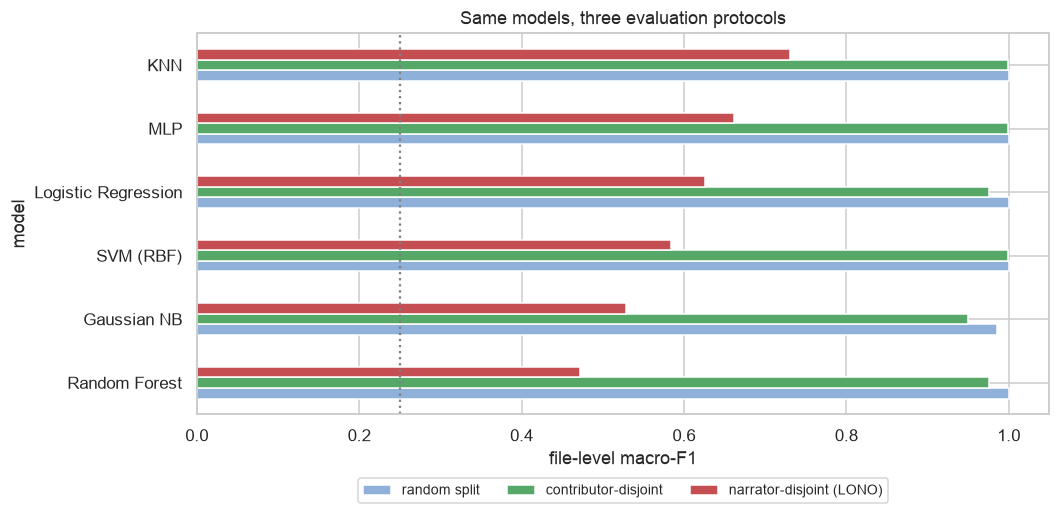

In [9]:
cmp = pd.concat({"random split": summary["file macro-F1"],
                 "contributor-disjoint": results["contributor_cv"]["file macro-F1"],
                 "narrator-disjoint (LONO)": results["narrator_lono"]["file macro-F1"]}, axis=1)
ax = cmp.sort_values("narrator-disjoint (LONO)").plot.barh(figsize=(10, 4.5), color=["#8fb0d9", "#55A868", "#C44E52"])
ax.set_xlabel("file-level macro-F1"); ax.set_xlim(0, 1.05); ax.axvline(0.25, ls=":", c="gray")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, fontsize=9); ax.set_title("Same models, three evaluation protocols")
plotting.save(ax.figure, "02_protocol_comparison")
cmp.round(3)

### Reading the results

* **Random split – saturated.** Five of six models classify all 144 test files correctly (Gaussian NB: 98.6 %), and the
  cross-validation scores used for model selection are ≥ 0.996 as well. This protocol cannot rank the models.
* **Contributor-disjoint – barely harder** (95–99.9 %). 13 of the 24 narrators are spread over several contributor folds,
  so a "new" contributor is usually reading from an audiobook the model has already heard.
* **Narrator-disjoint – the real task** (47–73 %). The ranking changes completely:
  **KNN on a 3-D LDA projection** is best (73 %), then MLP (65 %), Logistic Regression (62 %), SVM (58 %), Naïve Bayes (55 %)
  and Random Forest (47 %). The models that fit the training data most flexibly (RF, RBF-SVM) generalise worst: they
  exploit narrator- and recording-specific details. LDA keeps only the 3 directions that maximise *between-language*
  relative to *within-language* variance; since variation between narrators of one language is within-language variance,
  LDA suppresses voice-specific directions, and a simple neighbour vote in that space transfers best to new voices.

The 100 % scores on the random split therefore mostly measure *recognising the narrator* (each narrator reads one
language), not recognising the language. Detailed metrics and confusion matrices are in notebook 4.